Diferenças entre vizinhanças de quatro e oito posições

---

Bibliotecas

In [71]:
import cv2

import matplotlib.pyplot as plt
import networkx          as nx
import numpy             as np

---

Carregando a imagem do Josefran

In [72]:
josefran_image = cv2.imread("../../assets/josefran.jpg")
josefran_image = cv2.cvtColor(josefran_image, cv2.COLOR_BGR2GRAY)

josefran_image.shape

(640, 640)

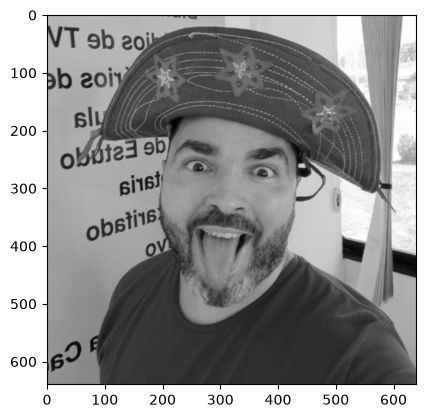

In [73]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [74]:
josefran_image = cv2.resize(josefran_image, (64, 64), cv2.INTER_LINEAR)
josefran_image.shape

(64, 64)

Visualização da imagem final

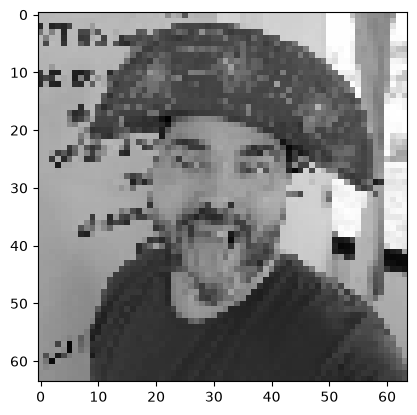

In [75]:
plt.imshow(josefran_image, cmap='gray')
plt.show()

---

Carregando a imagem de um ave

In [76]:
ave_image = cv2.imread("../../assets/ave.jpg")
ave_image = cv2.cvtColor(ave_image, cv2.COLOR_BGR2GRAY)

ave_image.shape

(3874, 4128)

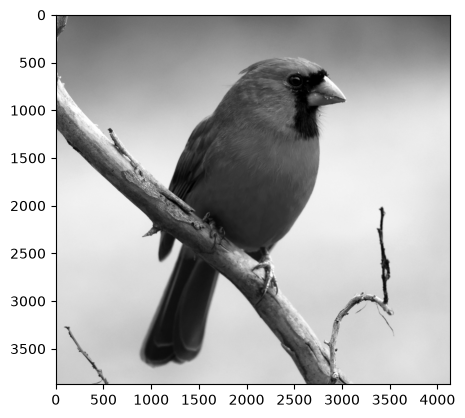

In [77]:
plt.imshow(ave_image, cmap='gray')
plt.show()

Redimensionando para $64\times64$

In [78]:
ave_image = cv2.resize(ave_image, (64, 64), cv2.INTER_LINEAR)
ave_image.shape

(64, 64)

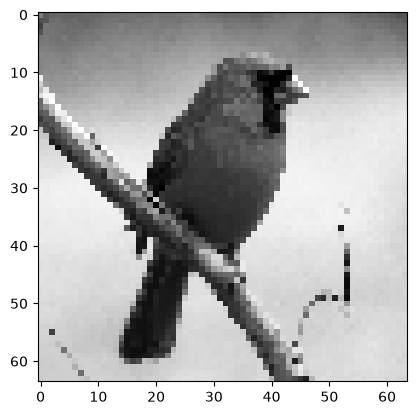

In [79]:
plt.imshow(ave_image, cmap='gray')
plt.show()

---

Algoritmo para construir a representação em grafos de uma imagem

In [80]:
def construir_grafo_imagem(matriz_pixels, vizinhanca=4, limiar=10):
    altura, largura = matriz_pixels.shape
    grafo           = { (i, j): [] for i in range(altura) for j in range(largura) }
    
    # Definir deslocamentos com base na vizinhança
    if vizinhanca == 4:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    elif vizinhanca == 8:
        direcoes = [(-1, 0), (1, 0), (0, -1), (0, 1), 
                    (-1, -1), (-1, 1), (1, -1), (1, 1)]
    else:
        raise ValueError("A vizinhança deve ser 4 ou 8.")

    for i in range(altura):
        for j in range(largura):
            u = (i, j)
            intensidade_u = matriz_pixels[i, j]
            
            for di, dj in direcoes:
                ni, nj = i + di, j + dj
                
                if 0 <= ni < altura and 0 <= nj < largura:
                    v = (ni, nj)
                    intensidade_v = matriz_pixels[ni, nj]
                    
                    if abs(int(intensidade_u) - int(intensidade_v)) <= limiar:
                        grafo[u].append(v)
                        
    return grafo

---

Visualização das imagens formada por diferentes vizinhaças

In [81]:
josefran_graph_4v = construir_grafo_imagem(josefran_image, vizinhanca = 4)
josefran_graph_8v = construir_grafo_imagem(josefran_image, vizinhanca = 8)

In [82]:
ave_graph_4v = construir_grafo_imagem(ave_image, vizinhanca = 4)
ave_graph_8v = construir_grafo_imagem(ave_image, vizinhanca = 8)

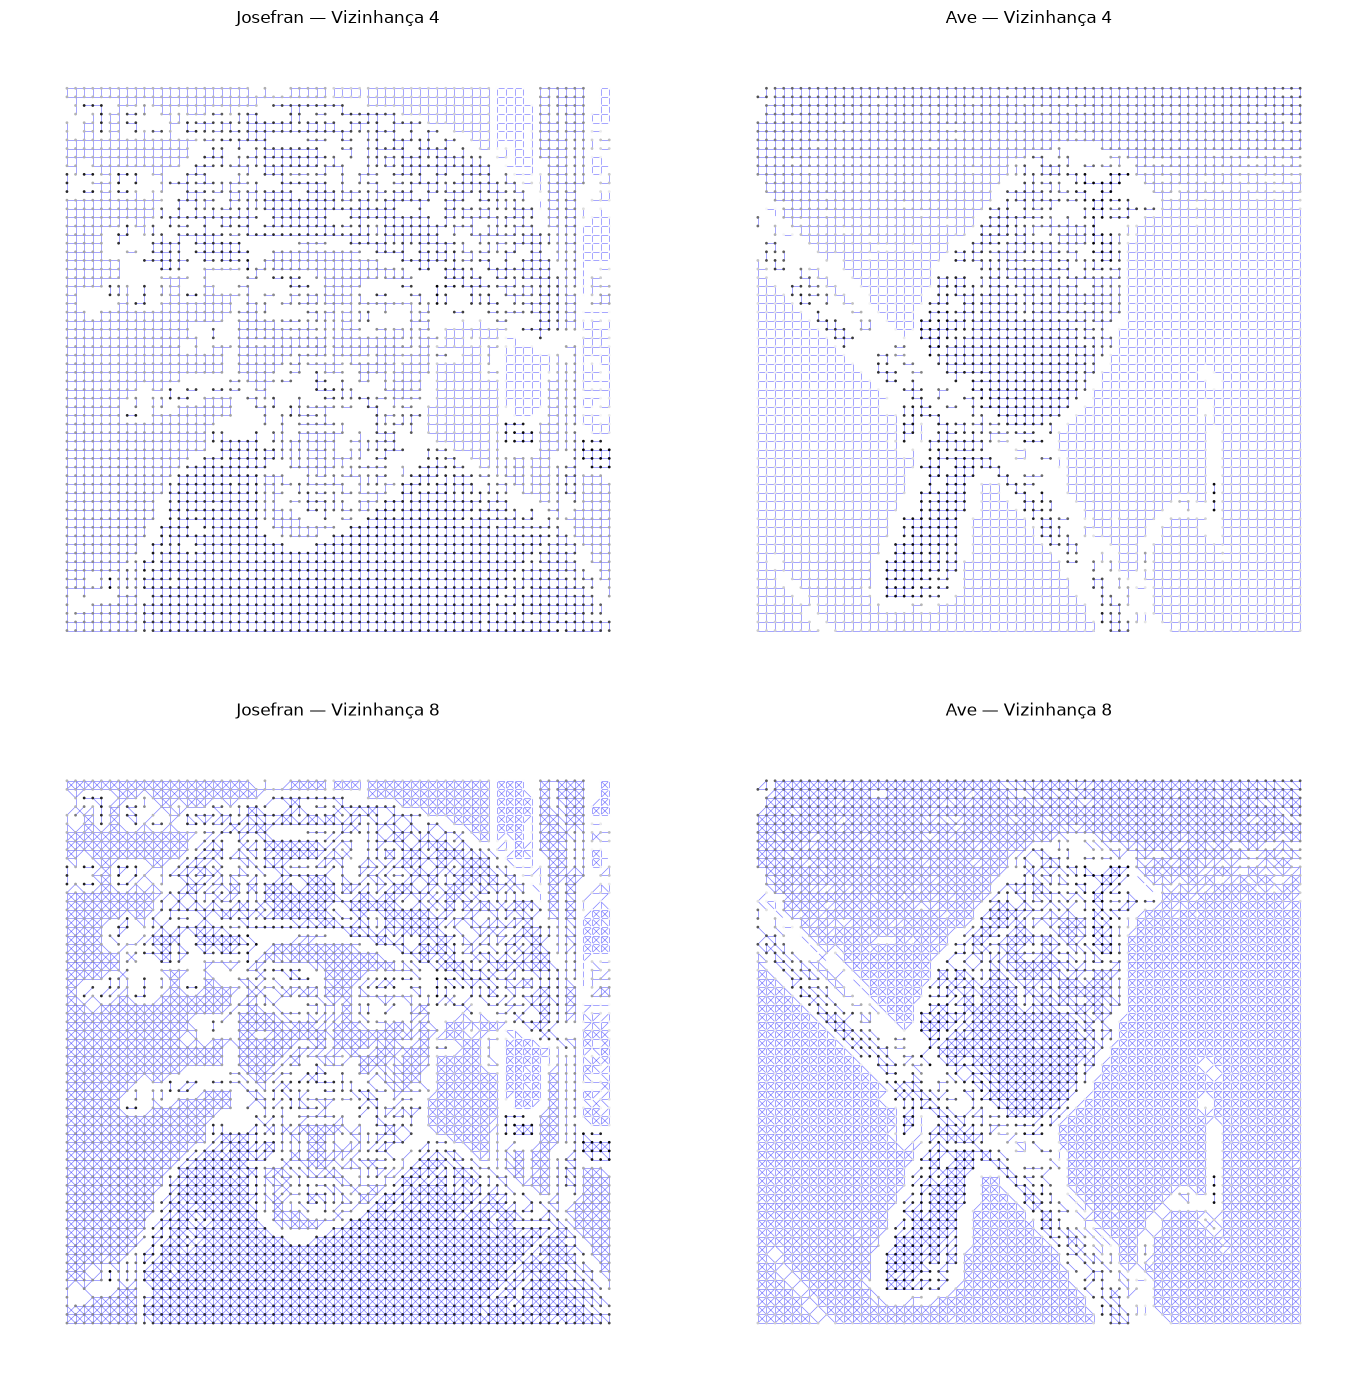

In [83]:
fig, axes = plt.subplots(2, 2, figsize=(14, 14))

configuracoes = [
    (0, 0, josefran_image, josefran_graph_4v, "Josefran — Vizinhança 4"),
    (1, 0, josefran_image, josefran_graph_8v, "Josefran — Vizinhança 8"),
    (0, 1, ave_image,      ave_graph_4v,      "Ave — Vizinhança 4"),
    (1, 1, ave_image,      ave_graph_8v,      "Ave — Vizinhança 8"),
]

for linha, coluna, matriz_pixels, grafo, titulo in configuracoes:
    ax = axes[linha, coluna]

    # 1. Converter dicionário de adjacência em grafo não direcionado
    G = nx.Graph()
    for u, vizinhos in grafo.items():
        for v in vizinhos:
            G.add_edge(u, v)

    # 2. Posição espacial alinhada à matriz da imagem (eixo y invertido)
    pos = {u: (u[1], -u[0]) for u in G.nodes()}

    # 3. Intensidade dos pixels para colorir os nós
    nodos = list(G.nodes())
    cores = [matriz_pixels[u[0], u[1]] for u in nodos]

    # 4. Desenhar no subplot correspondente
    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        nodelist=nodos,
        node_size=1,
        node_color=cores,
        cmap=plt.cm.gray,
    )
    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        width=0.5,
        alpha=0.5,
        edge_color="blue",
    )

    ax.set_title(titulo)
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()